In [1]:
# 1. تحميل مكتبة stb_image لقراءة وحفظ الصور في C++
!wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image.h
!wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image_write.h

# 2. رفع صورة من جهازك وتسميتها input.jpg تلقائياً
from google.colab import files
import shutil

print("اختر صورة من جهازك:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
shutil.move(filename, "input.jpg")
print("✅ تم تجهيز الصورة بنجاح باسم: input.jpg")

اختر صورة من جهازك:


Saving 1.jpeg to 1.jpeg
✅ تم تجهيز الصورة بنجاح باسم: input.jpg


In [2]:
%%writefile project.cpp
#include <iostream>
#include <vector>
#include <algorithm>
#include <cmath>

// تفعيل مكتبات قراءة وحفظ الصور في C++
#define STB_IMAGE_IMPLEMENTATION
#include "stb_image.h"
#define STB_IMAGE_WRITE_IMPLEMENTATION
#include "stb_image_write.h"

using namespace std;

// هيكل (Struct) لتمثيل البكسل الواحد (أحمر، أخضر، أزرق)
struct Pixel {
    unsigned char r, g, b;
};

// تعريف المصفوفة ثنائية الأبعاد للصورة
typedef vector<vector<Pixel>> ImageMatrix;

// 1. دالة تحويل الصورة لمصفوفة 2D
ImageMatrix loadImageToMatrix(const char* filename, int& width, int& height) {
    int channels;
    unsigned char* imgData = stbi_load(filename, &width, &height, &channels, 3);
    if (!imgData) {
        cout << "Error: Could not load image!" << endl;
        exit(1);
    }

    ImageMatrix matrix(height, vector<Pixel>(width));
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            int index = (y * width + x) * 3;
            matrix[y][x] = { imgData[index], imgData[index + 1], imgData[index + 2] };
        }
    }
    stbi_image_free(imgData);
    return matrix;
}

// 2. دالة حفظ المصفوفة كصورة جديدة
void saveMatrixToImage(const char* filename, const ImageMatrix& matrix, int width, int height) {
    vector<unsigned char> imgData(width * height * 3);
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            int index = (y * width + x) * 3;
            imgData[index]     = matrix[y][x].r;
            imgData[index + 1] = matrix[y][x].g;
            imgData[index + 2] = matrix[y][x].b;
        }
    }
    stbi_write_jpg(filename, width, height, 3, imgData.data(), 100);
}

// العملية الأولى: تحويل إلى درجات الرمادي (Grayscale)
ImageMatrix applyGrayscale(const ImageMatrix& img, int width, int height) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            // المعادلة الرياضية: Gray = 0.299R + 0.587G + 0.114B
            unsigned char gray = static_cast<unsigned char>(
                0.299 * img[y][x].r + 0.587 * img[y][x].g + 0.114 * img[y][x].b
            );
            result[y][x] = { gray, gray, gray };
        }
    }
    return result;
}

// العملية الثانية: تعديل السطوع (Brightness Adjustment)
ImageMatrix applyBrightness(const ImageMatrix& img, int width, int height, int value) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            // المعادلة: I_new = min(255, max(0, I_old + c))
            int newR = min(255, max(0, img[y][x].r + value));
            int newG = min(255, max(0, img[y][x].g + value));
            int newB = min(255, max(0, img[y][x].b + value));

            result[y][x] = {
                static_cast<unsigned char>(newR),
                static_cast<unsigned char>(newG),
                static_cast<unsigned char>(newB)
            };
        }
    }
    return result;
}

// العملية الثالثة: قلب الصورة أفقياً (Horizontal Flip)
ImageMatrix applyHorizontalFlip(const ImageMatrix& img, int width, int height) {
    ImageMatrix result(height, vector<Pixel>(width));
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            // المعادلة: x' = W - 1 - x
            result[y][width - 1 - x] = img[y][x];
        }
    }
    return result;
}

// العملية الرابعة: تحويل إلى أبيض وأسود (Black and White - Thresholding)
ImageMatrix applyBlackAndWhite(const ImageMatrix& img, int width, int height, int threshold = 128) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            unsigned char gray = static_cast<unsigned char>(
                0.299 * img[y][x].r + 0.587 * img[y][x].g + 0.114 * img[y][x].b
            );
            // إذا كانت القيمة >= 128 تصبح 255 (أبيض) وإلا 0 (أسود)
            unsigned char bw = (gray >= threshold) ? 255 : 0;
            result[y][x] = { bw, bw, bw };
        }
    }
    return result;
}

int main() {
    int width, height;
    ImageMatrix originalImg = loadImageToMatrix("input.jpg", width, height);
    cout << "Image loaded successfully! Dimensions: " << width << "x" << height << endl;

    int choice;
    cout << "\n========================================\n";
    cout << "   Image Processing Using Matrices\n";
    cout << "========================================\n";
    cout << "1. Grayscale\n";
    cout << "2. Brightness Adjustment\n";
    cout << "3. Horizontal Flip\n";
    cout << "4. Black and White\n";
    cout << "Enter your choice (1-4): ";
    cin >> choice;

    ImageMatrix processedImg;

    if (choice == 1) {
        processedImg = applyGrayscale(originalImg, width, height);
        cout << "Applied Grayscale!\n";
    }
    else if (choice == 2) {
        int brightnessVal;
        cout << "Enter brightness value (e.g., 50 to increase, -50 to decrease): ";
        cin >> brightnessVal;
        processedImg = applyBrightness(originalImg, width, height, brightnessVal);
        cout << "Applied Brightness Adjustment!\n";
    }
    else if (choice == 3) {
        processedImg = applyHorizontalFlip(originalImg, width, height);
        cout << "Applied Horizontal Flip!\n";
    }
    else if (choice == 4) {
        processedImg = applyBlackAndWhite(originalImg, width, height, 128);
        cout << "Applied Black and White!\n";
    }
    else {
        cout << "Invalid choice!\n";
        return 0;
    }

    saveMatrixToImage("output.jpg", processedImg, width, height);
    cout << "Saved processed image as output.jpg\n";

    return 0;
}

Writing project.cpp


In [4]:
!g++ project.cpp -o project && ./project

Image loaded successfully! Dimensions: 564x832

   Image Processing Using Matrices
1. Grayscale
2. Brightness Adjustment
3. Horizontal Flip
4. Black and White
Enter your choice (1-4): 1
Applied Grayscale!
Saved processed image as output.jpg


In [6]:
%%writefile project.cpp
#include <iostream>
#include <vector>
#include <algorithm>

#define STB_IMAGE_IMPLEMENTATION
#include "stb_image.h"
#define STB_IMAGE_WRITE_IMPLEMENTATION
#include "stb_image_write.h"

using namespace std;

struct Pixel {
    unsigned char r, g, b;
};

typedef vector<vector<Pixel>> ImageMatrix;

// 1. قراءة الصورة وتحويلها لمصفوفة
ImageMatrix loadImageToMatrix(const char* filename, int& width, int& height) {
    int channels;
    unsigned char* imgData = stbi_load(filename, &width, &height, &channels, 3);
    if (!imgData) {
        cout << "Error: Could not load input.jpg!" << endl;
        exit(1);
    }

    ImageMatrix matrix(height, vector<Pixel>(width));
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            int index = (y * width + x) * 3;
            matrix[y][x] = { imgData[index], imgData[index + 1], imgData[index + 2] };
        }
    }
    stbi_image_free(imgData);
    return matrix;
}

// 2. حفظ المصفوفة كصورة
void saveMatrixToImage(const char* filename, const ImageMatrix& matrix, int width, int height) {
    vector<unsigned char> imgData(width * height * 3);
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            int index = (y * width + x) * 3;
            imgData[index]     = matrix[y][x].r;
            imgData[index + 1] = matrix[y][x].g;
            imgData[index + 2] = matrix[y][x].b;
        }
    }
    stbi_write_jpg(filename, width, height, 3, imgData.data(), 100);
}

// العملية 1: Grayscale
ImageMatrix applyGrayscale(const ImageMatrix& img, int width, int height) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            unsigned char gray = static_cast<unsigned char>(
                0.299 * img[y][x].r + 0.587 * img[y][x].g + 0.114 * img[y][x].b
            );
            result[y][x] = { gray, gray, gray };
        }
    }
    return result;
}

// العملية 2: Brightness Adjustment
ImageMatrix applyBrightness(const ImageMatrix& img, int width, int height, int value) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            int newR = min(255, max(0, img[y][x].r + value));
            int newG = min(255, max(0, img[y][x].g + value));
            int newB = min(255, max(0, img[y][x].b + value));
            result[y][x] = {
                static_cast<unsigned char>(newR),
                static_cast<unsigned char>(newG),
                static_cast<unsigned char>(newB)
            };
        }
    }
    return result;
}

// العملية 3: Horizontal Flip
ImageMatrix applyHorizontalFlip(const ImageMatrix& img, int width, int height) {
    ImageMatrix result(height, vector<Pixel>(width));
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            result[y][width - 1 - x] = img[y][x];
        }
    }
    return result;
}

// العملية 4: Black and White (Thresholding)
ImageMatrix applyBlackAndWhite(const ImageMatrix& img, int width, int height, int threshold = 128) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            unsigned char gray = static_cast<unsigned char>(
                0.299 * img[y][x].r + 0.587 * img[y][x].g + 0.114 * img[y][x].b
            );
            unsigned char bw = (gray >= threshold) ? 255 : 0;
            result[y][x] = { bw, bw, bw };
        }
    }
    return result;
}

int main() {
    int width, height;
    ImageMatrix originalImg = loadImageToMatrix("input.jpg", width, height);
    cout << "Image Loaded! Dimensions: " << width << "x" << height << endl;

    int brightnessVal;
    cout << "Enter brightness value (e.g., 50 to increase, -50 to decrease): ";
    cin >> brightnessVal;

    // تنفيذ العمليات الأربعة وحفظ كل صورة باسم منفصل
    ImageMatrix grayImg = applyGrayscale(originalImg, width, height);
    saveMatrixToImage("out_grayscale.jpg", grayImg, width, height);
    cout << "1. Saved out_grayscale.jpg\n";

    ImageMatrix brightImg = applyBrightness(originalImg, width, height, brightnessVal);
    saveMatrixToImage("out_brightness.jpg", brightImg, width, height);
    cout << "2. Saved out_brightness.jpg\n";

    ImageMatrix flipImg = applyHorizontalFlip(originalImg, width, height);
    saveMatrixToImage("out_flipped.jpg", flipImg, width, height);
    cout << "3. Saved out_flipped.jpg\n";

    ImageMatrix bwImg = applyBlackAndWhite(originalImg, width, height, 128);
    saveMatrixToImage("out_bw.jpg", bwImg, width, height);
    cout << "4. Saved out_bw.jpg\n";

    cout << "\nAll 4 operations completed successfully!\n";
    return 0;
}

Overwriting project.cpp


Image Loaded! Dimensions: 564x832
Enter brightness value (e.g., 50 to increase, -50 to decrease): 50
1. Saved out_grayscale.jpg
2. Saved out_brightness.jpg
3. Saved out_flipped.jpg
4. Saved out_bw.jpg

All 4 operations completed successfully!


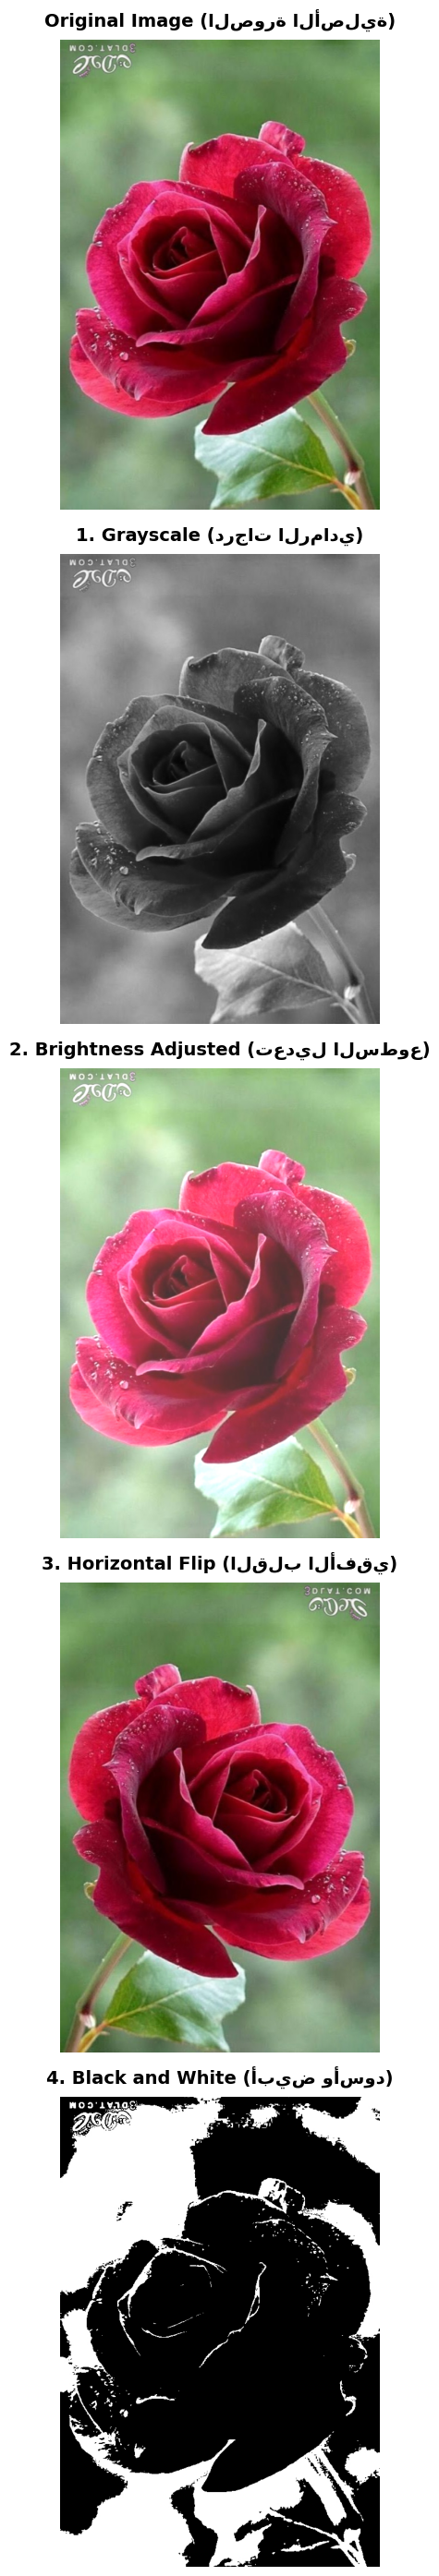

In [7]:
# 1. ترجمة وتشغيل برنامج C++
!g++ -O3 project.cpp -o project && ./project

# 2. عرض الصورة الأصلية والأربع تعديلات تحت بعض
import matplotlib.pyplot as plt
import cv2

images = [
    ("Original Image (الصورة الأصلية)", "input.jpg"),
    ("1. Grayscale (درجات الرمادي)", "out_grayscale.jpg"),
    ("2. Brightness Adjusted (تعديل السطوع)", "out_brightness.jpg"),
    ("3. Horizontal Flip (القلب الأفقي)", "out_flipped.jpg"),
    ("4. Black and White (أبيض وأسود)", "out_bw.jpg")
]

plt.figure(figsize=(8, 28)) # حجم طويل لعرض الصور تحت بعض بوضوح

for i, (title, filename) in enumerate(images, 1):
    img = cv2.cvtColor(cv2.imread(filename), cv2.COLOR_BGR2RGB)
    plt.subplot(5, 1, i) # 5 صفوف تحت بعض في عمود واحد
    plt.imshow(img)
    plt.title(title, fontsize=14, fontweight='bold', pad=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# 1. ترجمة كود C++ اللي عملناه في الخطوة اللي فاتت
!g++ -O3 project.cpp -o project_cpp

# 2. تشغيل واجهة البرنامج التفاعلية جوه Colab
import gradio as gr
import subprocess
from PIL import Image

def run_cpp_program(input_img, brightness_val):
    if input_img is None:
        return None, None, None, None

    # حفظ الصورة اللي اخترتها من جهازك
    input_img.save("input.jpg")

    # تشغيل برنامج C++ وتمرير قيمة السطوع له تلقائياً
    subprocess.run(
        ["./project_cpp"],
        input=f"{int(brightness_val)}\n",
        text=True,
        check=True
    )

    # قراءة الأربع صور الناتجة من C++ وعرضها
    gray = Image.open("out_grayscale.jpg")
    bright = Image.open("out_brightness.jpg")
    flip = Image.open("out_flipped.jpg")
    bw = Image.open("out_bw.jpg")

    return gray, bright, flip, bw

with gr.Blocks(theme=gr.themes.Soft()) as app:
    gr.Markdown("# 🖼️ Image Processing Using Matrices (C++ Program)")
    gr.Markdown("ارفع صورتك من جهازك، حدد درجة السطوع، واضغط على الزر لتنفيذ الأربع عمليات باستخدام مصفوفات **C++**.")

    # الجزء العلوي: إدخال الصورة والتحكم
    input_image = gr.Image(type="pil", label="1. ارفع الصورة الأصلية هنا (Original Image)")
    brightness_slider = gr.Slider(
        minimum=-150, maximum=150, value=50, step=5,
        label="2. اختر مقدار السطوع (Brightness Value: موجب للزيادة، سالب للتقليل)"
    )
    process_btn = gr.Button("🚀 تطبيق التعديلات الأربعة (Run C++ Engine)", variant="primary")

    gr.Markdown("---")
    gr.Markdown("### النتائج بعد المعالجة (اضغط على أيقونة التحميل أعلى يمين كل صورة لحفظها):")

    # عرض الأربع تعديلات تحت بعض
    out1 = gr.Image(type="pil", label="1. Grayscale (درجات الرمادي)")
    out2 = gr.Image(type="pil", label="2. Brightness Adjusted (تعديل السطوع)")
    out3 = gr.Image(type="pil", label="3. Horizontal Flip (القلب الأفقي)")
    out4 = gr.Image(type="pil", label="4. Black and White (أبيض وأسود)")

    process_btn.click(
        fn=run_cpp_program,
        inputs=[input_image, brightness_slider],
        outputs=[out1, out2, out3, out4]
    )

app.launch(share=True)

/tmp/ipykernel_1759/2225905605.py:32: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3d098cb3374348ced3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [9]:
# 1. ترجمة كود C++
!g++ -O3 project.cpp -o project_cpp

import gradio as gr
import subprocess
from PIL import Image

# ==========================================
# بيانات المشروع والدكتورة وأعضاء الفريق
# ==========================================
PROJECT_TITLE = "Image Processing Using Matrices"
SUPERVISOR_NAME = "Supervised by: Dr. Eman Gaber"
TEAM_MEMBERS = [
    "👑 Anas Hassan (Leader)",
    "👤 Mariam Essam",
    "👤 Mariam Sherif",
    "👤 Noura Nasr",
    "👤 Ali Ahmed",
    "👤 Hager Mohamed"
]
# ==========================================

# دالة تشغيل كود C++ لكل العمليات
def run_cpp_all(input_img, brightness_val):
    if input_img is None:
        return None, None, None, None
    input_img.save("input.jpg")
    subprocess.run(
        ["./project_cpp"],
        input=f"{int(brightness_val)}\n",
        text=True,
        check=True
    )
    return (
        Image.open("out_grayscale.jpg"),
        Image.open("out_brightness.jpg"),
        Image.open("out_flipped.jpg"),
        Image.open("out_bw.jpg")
    )

# دالة الاستوديو التفاعلي (ترجع صورة واحدة حسب الاختيار)
def process_single(input_img, operation, brightness_val):
    if input_img is None:
        return None
    gray, bright, flip, bw = run_cpp_all(input_img, brightness_val)
    if operation == "Grayscale":
        return gray
    elif operation == "Brightness Adjustment":
        return bright
    elif operation == "Horizontal Flip":
        return flip
    elif operation == "Black and White":
        return bw
    return input_img

# قراءة كود C++ لعرضه في التبويب الثالث
with open("project.cpp", "r") as f:
    cpp_source_code = f.read()

# تنسيق CSS مخصص لمحاكاة التصميم الاحترافي
custom_css = """
body, .gradio-container {
    background-color: #0f111a !important;
    color: #ffffff !important;
    font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
}
.header-box {
    background: linear-gradient(135deg, #1a1c2e 0%, #251d3a 100%);
    border: 1px solid #3b3561;
    border-radius: 16px;
    padding: 20px;
    text-align: center;
    margin-bottom: 15px;
    box-shadow: 0 8px 24px rgba(0,0,0,0.4);
}
.supervisor-badge {
    display: inline-block;
    background: #2b244d;
    border: 1px solid #6c5ce7;
    color: #d6cfff;
    padding: 6px 18px;
    border-radius: 20px;
    font-weight: bold;
    font-size: 14px;
    margin-bottom: 14px;
}
.team-container {
    display: flex;
    flex-wrap: wrap;
    justify-content: center;
    gap: 10px;
}
.member-badge {
    background: #181b28;
    border: 1px solid #383e56;
    color: #e2e8f0;
    padding: 6px 14px;
    border-radius: 20px;
    font-size: 13px;
    font-weight: 500;
}
.leader-badge {
    background: linear-gradient(90deg, #4c3575, #372948);
    border: 1px solid #9b72cf;
    color: #fff;
    font-weight: bold;
}
.panel-title-orig {
    background: linear-gradient(90deg, #132a3a, #1b3b4e);
    border: 1px solid #2c5e7a;
    color: #7dd3fc;
    text-align: center;
    padding: 10px;
    border-radius: 10px;
    font-weight: bold;
    font-size: 16px;
    margin-bottom: 8px;
}
.panel-title-proc {
    background: linear-gradient(90deg, #2d1b46, #3d225e);
    border: 1px solid #6d3fa8;
    color: #e879f9;
    text-align: center;
    padding: 10px;
    border-radius: 10px;
    font-weight: bold;
    font-size: 16px;
    margin-bottom: 8px;
}
.arrow-box {
    display: flex;
    align-items: center;
    justify-content: center;
    height: 380px;
    font-size: 36px;
    color: #8b5cf6;
    font-weight: bold;
}
"""

# بناء الهيدر HTML
team_html = "".join([
    f'<span class="member-badge {"leader-badge" if i == 0 else ""}">{name}</span>'
    for i, name in enumerate(TEAM_MEMBERS)
])

header_html = f"""
<div class="header-box">
    <h1 style="margin:0 0 12px 0; font-size:26px; color:#fff;">🖼️ {PROJECT_TITLE} (C++ Engine)</h1>
    <div class="supervisor-badge">🎓 {SUPERVISOR_NAME}</div>
    <div class="team-container">{team_html}</div>
</div>
"""

with gr.Blocks(css=custom_css, theme=gr.themes.Base()) as app:
    gr.HTML(header_html)

    with gr.Tabs():
        # التبويب الأول: الاستوديو التفاعلي
        with gr.Tab("🎛️ الاستوديو التفاعلي"):
            with gr.Row():
                with gr.Column(scale=5):
                    gr.HTML('<div class="panel-title-orig">🖼️ الصورة الأصلية</div>')
                    studio_in = gr.Image(type="pil", show_label=False, height=360)

                with gr.Column(scale=1, min_width=50):
                    gr.HTML('<div class="arrow-box">⬅️</div>')

                with gr.Column(scale=5):
                    gr.HTML('<div class="panel-title-proc">✨ الصورة المعدلة</div>')
                    studio_out = gr.Image(type="pil", show_label=False, height=360)

            with gr.Row():
                op_selector = gr.Radio(
                    ["Grayscale", "Brightness Adjustment", "Horizontal Flip", "Black and White"],
                    value="Grayscale",
                    label="اختر العملية المطلوبة (Matrix Operation)"
                )
                bright_slider = gr.Slider(
                    minimum=-150, maximum=150, value=50, step=5,
                    label="مقدار السطوع (Brightness Value)"
                )
            apply_btn = gr.Button("🚀 تنفيذ التعديل باستخدام C++", variant="primary")

            apply_btn.click(
                fn=process_single,
                inputs=[studio_in, op_selector, bright_slider],
                outputs=studio_out
            )

        # التبويب الثاني: عرض العمليات الأربع دفعة واحدة
        with gr.Tab("🖼️ العمليات الأربع"):
            with gr.Row():
                all_in = gr.Image(type="pil", label="ارفع الصورة الأصلية", height=250)
                with gr.Column():
                    all_bright_slider = gr.Slider(-150, 150, value=50, step=5, label="مقدار السطوع")
                    run_all_btn = gr.Button("⚡ تطبيق وعرض العمليات الأربع معاً", variant="primary")

            with gr.Row():
                out_gray = gr.Image(type="pil", label="1. Grayscale (درجات الرمادي)")
                out_bright = gr.Image(type="pil", label="2. Brightness (تعديل السطوع)")
            with gr.Row():
                out_flip = gr.Image(type="pil", label="3. Horizontal Flip (القلب الأفقي)")
                out_bw = gr.Image(type="pil", label="4. Black & White (أبيض وأسود)")

            run_all_btn.click(
                fn=run_cpp_all,
                inputs=[all_in, all_bright_slider],
                outputs=[out_gray, out_bright, out_flip, out_bw]
            )

        # التبويب الثالث: كود الـ C++ والمعادلات
        with gr.Tab("💻 كود الـ C++"):
            gr.Markdown("### الكود المصدري المنفذ للمصفوفات (`project.cpp`)")
            gr.Code(value=cpp_source_code, language="cpp")

app.launch(share=True)

/tmp/ipykernel_1759/1417106948.py:155: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Base()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ddafc6807245b16bbe.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [10]:
%%writefile project.cpp
#include <iostream>
#include <vector>
#include <algorithm>
#include <string>
#include <cstdio>
#include <cstdlib>

#define STB_IMAGE_IMPLEMENTATION
#include "stb_image.h"
#define STB_IMAGE_WRITE_IMPLEMENTATION
#include "stb_image_write.h"

using namespace std;

struct Pixel {
    unsigned char r, g, b;
};

typedef vector<vector<Pixel>> ImageMatrix;

ImageMatrix loadImageToMatrix(const char* filename, int& width, int& height) {
    int channels;
    unsigned char* imgData = stbi_load(filename, &width, &height, &channels, 3);
    if (!imgData) exit(1);

    ImageMatrix matrix(height, vector<Pixel>(width));
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            int index = (y * width + x) * 3;
            matrix[y][x] = { imgData[index], imgData[index + 1], imgData[index + 2] };
        }
    }
    stbi_image_free(imgData);
    return matrix;
}

void saveMatrixToImage(const char* filename, const ImageMatrix& matrix, int width, int height) {
    vector<unsigned char> imgData(width * height * 3);
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            int index = (y * width + x) * 3;
            imgData[index]     = matrix[y][x].r;
            imgData[index + 1] = matrix[y][x].g;
            imgData[index + 2] = matrix[y][x].b;
        }
    }
    stbi_write_jpg(filename, width, height, 3, imgData.data(), 100);
}

ImageMatrix applyGrayscale(const ImageMatrix& img, int width, int height) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            unsigned char gray = static_cast<unsigned char>(
                0.299 * img[y][x].r + 0.587 * img[y][x].g + 0.114 * img[y][x].b
            );
            result[y][x] = { gray, gray, gray };
        }
    }
    return result;
}

ImageMatrix applyBrightness(const ImageMatrix& img, int width, int height, int value) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            int newR = min(255, max(0, img[y][x].r + value));
            int newG = min(255, max(0, img[y][x].g + value));
            int newB = min(255, max(0, img[y][x].b + value));
            result[y][x] = {
                static_cast<unsigned char>(newR),
                static_cast<unsigned char>(newG),
                static_cast<unsigned char>(newB)
            };
        }
    }
    return result;
}

ImageMatrix applyHorizontalFlip(const ImageMatrix& img, int width, int height) {
    ImageMatrix result(height, vector<Pixel>(width));
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            result[y][width - 1 - x] = img[y][x];
        }
    }
    return result;
}

ImageMatrix applyBlackAndWhite(const ImageMatrix& img, int width, int height, int threshold) {
    ImageMatrix result = img;
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            unsigned char gray = static_cast<unsigned char>(
                0.299 * img[y][x].r + 0.587 * img[y][x].g + 0.114 * img[y][x].b
            );
            unsigned char bw = (gray >= threshold) ? 255 : 0;
            result[y][x] = { bw, bw, bw };
        }
    }
    return result;
}

// دالة طباعة عينة 4x4 من منتصف المصفوفة قبل وبعد التعديل
void printMatrixLog(const ImageMatrix& orig, const ImageMatrix& proc, int width, int height, bool isSingleChannel) {
    int startY = max(0, height / 2 - 2);
    int startX = max(0, width / 2 - 2);
    int endY = min(height, startY + 4);
    int endX = min(width, startX + 4);

    printf("Input Matrix Dimensions : %d x %d x 3 (RGB Matrix)\n", height, width);
    printf("Output Matrix Dimensions: %d x %d x %s\n\n", height, width,
           isSingleChannel ? "1 (2D Grayscale/Binary Matrix)" : "3 (RGB Matrix)");

    printf("--- [BEFORE] Original Matrix Sample (4x4 at Center) ---\n");
    for (int y = startY; y < endY; y++) {
        printf("[ ");
        for (int x = startX; x < endX; x++) {
            printf("(%3d,%3d,%3d) ", orig[y][x].r, orig[y][x].g, orig[y][x].b);
        }
        printf("]\n");
    }

    printf("\n--- [AFTER] Processed Matrix Sample (4x4 at Center) ---\n");
    for (int y = startY; y < endY; y++) {
        printf("[ ");
        for (int x = startX; x < endX; x++) {
            if (isSingleChannel) {
                printf(" %3d ", proc[y][x].r);
            } else {
                printf("(%3d,%3d,%3d) ", proc[y][x].r, proc[y][x].g, proc[y][x].b);
            }
        }
        printf("]\n");
    }
}

int main(int argc, char* argv[]) {
    if (argc < 4) return 1;
    string mode = argv[1];
    int brightnessVal = atoi(argv[2]);
    int thresholdVal = atoi(argv[3]);

    int width, height;
    ImageMatrix originalImg = loadImageToMatrix("input.jpg", width, height);

    if (mode == "all") {
        saveMatrixToImage("out_grayscale.jpg", applyGrayscale(originalImg, width, height), width, height);
        saveMatrixToImage("out_brightness.jpg", applyBrightness(originalImg, width, height, brightnessVal), width, height);
        saveMatrixToImage("out_flipped.jpg", applyHorizontalFlip(originalImg, width, height), width, height);
        saveMatrixToImage("out_bw.jpg", applyBlackAndWhite(originalImg, width, height, thresholdVal), width, height);
        return 0;
    }

    ImageMatrix processedImg;
    bool isSingleChannel = false;

    if (mode == "Grayscale") {
        processedImg = applyGrayscale(originalImg, width, height);
        isSingleChannel = true;
    } else if (mode == "Brightness") {
        processedImg = applyBrightness(originalImg, width, height, brightnessVal);
    } else if (mode == "Flip") {
        processedImg = applyHorizontalFlip(originalImg, width, height);
    } else if (mode == "BW") {
        processedImg = applyBlackAndWhite(originalImg, width, height, thresholdVal);
        isSingleChannel = true;
    } else {
        processedImg = originalImg;
    }

    saveMatrixToImage("output.jpg", processedImg, width, height);
    printMatrixLog(originalImg, processedImg, width, height, isSingleChannel);
    return 0;
}

Overwriting project.cpp


In [11]:
# 1. ترجمة كود C++
!g++ -O3 project.cpp -o project_cpp

import gradio as gr
import subprocess
from PIL import Image

PROJECT_TITLE = "Image Processing Using Matrices"
SUPERVISOR_NAME = "Supervised by: Dr. Eman Gaber"
TEAM_MEMBERS = [
    "👑 Anas Hassan (Leader)",
    "👤 Mariam Essam",
    "👤 Mariam Sherif",
    "👤 Noura Nasr",
    "👤 Ali Ahmed",
    "👤 Hager Mohamed"
]

# ربط أسماء العمليات في الواجهة بأوامر C++
OP_MAP = {
    "🎨 Grayscale (تحويل لرمادي)": "Grayscale",
    "☀️ Brightness (تحويل السطوع)": "Brightness",
    "🔄 Horizontal Flip (عكس أفقي)": "Flip",
    "🏁 Black & White (أبيض وأسود)": "BW"
}

def process_single(input_img, operation_label, brightness_val, threshold_val):
    if input_img is None:
        return None, "⚠️ يرجى رفع صورة أولاً لعرض مصفوفة البكسلات..."
    input_img.save("input.jpg")
    op_code = OP_MAP[operation_label]

    # تشغيل C++ والتقاط مخرجات المصفوفة الحية
    res = subprocess.run(
        ["./project_cpp", op_code, str(int(brightness_val)), str(int(threshold_val))],
        capture_output=True, text=True, check=True
    )
    return Image.open("output.jpg"), res.stdout

def run_cpp_all(input_img, brightness_val, threshold_val):
    if input_img is None:
        return None, None, None, None
    input_img.save("input.jpg")
    subprocess.run(
        ["./project_cpp", "all", str(int(brightness_val)), str(int(threshold_val))],
        check=True
    )
    return (
        Image.open("out_grayscale.jpg"),
        Image.open("out_brightness.jpg"),
        Image.open("out_flipped.jpg"),
        Image.open("out_bw.jpg")
    )

with open("project.cpp", "r") as f:
    cpp_source_code = f.read()

custom_css = """
body, .gradio-container {
    background-color: #0b0d14 !important;
    color: #ffffff !important;
    font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
}
.header-box {
    background: linear-gradient(135deg, #161826 0%, #231a38 100%);
    border: 1px solid #38325c;
    border-radius: 16px;
    padding: 18px;
    text-align: center;
    margin-bottom: 15px;
    box-shadow: 0 8px 24px rgba(0,0,0,0.5);
}
.supervisor-badge {
    display: inline-block;
    background: #282047;
    border: 1px solid #7c3aed;
    color: #ddd6fe;
    padding: 5px 18px;
    border-radius: 20px;
    font-weight: bold;
    font-size: 14px;
    margin-bottom: 12px;
}
.team-container {
    display: flex;
    flex-wrap: wrap;
    justify-content: center;
    gap: 8px;
}
.member-badge {
    background: #141722;
    border: 1px solid #333952;
    color: #e2e8f0;
    padding: 5px 14px;
    border-radius: 20px;
    font-size: 13px;
}
.leader-badge {
    background: linear-gradient(90deg, #4c3575, #372948);
    border: 1px solid #a78bfa;
    color: #fff;
    font-weight: bold;
}
.panel-title-orig {
    background: linear-gradient(90deg, #112636, #19384d);
    border: 1px solid #285673;
    color: #7dd3fc;
    text-align: center;
    padding: 10px;
    border-radius: 10px;
    font-weight: bold;
    font-size: 16px;
    margin-bottom: 8px;
}
.panel-title-proc {
    background: linear-gradient(90deg, #2a1842, #3a2059);
    border: 1px solid #6b3fa0;
    color: #e879f9;
    text-align: center;
    padding: 10px;
    border-radius: 10px;
    font-weight: bold;
    font-size: 16px;
    margin-bottom: 8px;
}
.arrow-box {
    display: flex;
    align-items: center;
    justify-content: center;
    height: 360px;
    font-size: 38px;
    color: #a855f7;
    text-shadow: 0 0 15px rgba(168, 85, 247, 0.6);
}
.section-header {
    color: #7dd3fc;
    font-size: 16px;
    font-weight: bold;
    border-bottom: 1px solid #283044;
    padding-bottom: 8px;
    margin-bottom: 12px;
}
.dark-card {
    background-color: #131620 !important;
    border: 1px solid #262b3d !important;
    border-radius: 14px !important;
    padding: 16px !important;
}
/* تنسيق أزرار الاختيارات لتكون كروت داكنة احترافية */
.custom-radio .wrap {
    display: flex !important;
    flex-direction: column !important;
    gap: 10px !important;
}
.custom-radio label {
    background: #1c202e !important;
    border: 1px solid #32384d !important;
    border-radius: 10px !important;
    padding: 12px 16px !important;
    color: #f1f5f9 !important;
    font-weight: bold !important;
    font-size: 15px !important;
    transition: all 0.2s ease;
}
.custom-radio label:hover {
    border-color: #8b5cf6 !important;
    background: #252a3d !important;
}
/* تنسيق شاشة المصفوفة الحية */
.matrix-terminal textarea {
    background-color: #05080a !important;
    color: #00ff66 !important;
    font-family: 'Courier New', Courier, monospace !important;
    font-size: 13px !important;
    line-height: 1.45 !important;
    border: 1px solid #1e3a2f !important;
    border-radius: 10px !important;
    direction: ltr !important;
    text-align: left !important;
}
/* تنسيق زرار التطبيق المتدرج */
.gradient-btn {
    background: linear-gradient(90deg, #0ea5e9 0%, #8b5cf6 100%) !important;
    border: none !important;
    color: white !important;
    font-weight: bold !important;
    font-size: 16px !important;
    padding: 14px !important;
    border-radius: 12px !important;
    box-shadow: 0 4px 15px rgba(139, 92, 246, 0.4) !important;
    margin-top: 10px !important;
}
.gradient-btn:hover {
    opacity: 0.92 !important;
    transform: translateY(-1px);
}
"""

team_html = "".join([
    f'<span class="member-badge {"leader-badge" if i == 0 else ""}">{name}</span>'
    for i, name in enumerate(TEAM_MEMBERS)
])

header_html = f"""
<div class="header-box">
    <h1 style="margin:0 0 10px 0; font-size:24px; color:#fff;">🖼️ {PROJECT_TITLE} (C++ Engine)</h1>
    <div class="supervisor-badge">🎓 {SUPERVISOR_NAME}</div>
    <div class="team-container">{team_html}</div>
</div>
"""

with gr.Blocks(css=custom_css, theme=gr.themes.Base()) as app:
    gr.HTML(header_html)

    with gr.Tabs():
        # التبويب الأول: الاستوديو التفاعلي
        with gr.Tab("🎛️ الاستوديو التفاعلي"):
            # الصف العلوي: الصورتين وبينهم السهم
            with gr.Row():
                with gr.Column(scale=5):
                    gr.HTML('<div class="panel-title-orig">🖼️ الصورة الأصلية</div>')
                    studio_in = gr.Image(type="pil", show_label=False, height=340)

                with gr.Column(scale=1, min_width=50):
                    # تم تعديل السهم ليشير من اليسار لليمين (من الأصلية للمعدلة)
                    gr.HTML('<div class="arrow-box">➡️</div>')

                with gr.Column(scale=5):
                    gr.HTML('<div class="panel-title-proc">✨ الصورة المعدلة</div>')
                    studio_out = gr.Image(type="pil", show_label=False, height=340)

            # الصف السفلي: العمليات + المصفوفة الحية على اليسار، ومعاملات الضبط على اليمين
            with gr.Row():
                # العمود الأيسر: العمليات + شاشة المصفوفة
                with gr.Column(scale=1, elem_classes="dark-card"):
                    gr.HTML('<div class="section-header">🧮 اختر العملية الرياضية</div>')
                    op_selector = gr.Radio(
                        list(OP_MAP.keys()),
                        value="🎨 Grayscale (تحويل لرمادي)",
                        show_label=False,
                        elem_classes="custom-radio"
                    )
                    gr.HTML('<div class="section-header" style="margin-top:16px;">📟 مصفوفة البكسلات الحية (C++ Matrix)</div>')
                    matrix_display = gr.Textbox(
                        lines=14,
                        max_lines=14,
                        show_label=False,
                        interactive=False,
                        value="Upload an image and click 'تطبيق وتحديث المصفوفة' to inspect live 2D pixel matrices...",
                        elem_classes="matrix-terminal"
                    )

                # العمود الأيمن: معاملات الضبط + زرار التنفيذ
                with gr.Column(scale=1, elem_classes="dark-card"):
                    gr.HTML('<div class="section-header">🎛️ معاملات الضبط</div>')
                    bright_slider = gr.Slider(
                        minimum=-150, maximum=150, value=60, step=5,
                        label="☀️ السطوع (Brightness β)"
                    )
                    thresh_slider = gr.Slider(
                        minimum=0, maximum=255, value=127, step=1,
                        label="🏁 عتبة الأبيض والأسود (Threshold)"
                    )
                    apply_btn = gr.Button(
                        "⚡ تطبيق وتحديث المصفوفة",
                        elem_classes="gradient-btn"
                    )

            apply_btn.click(
                fn=process_single,
                inputs=[studio_in, op_selector, bright_slider, thresh_slider],
                outputs=[studio_out, matrix_display]
            )

        # التبويب الثاني: العمليات الأربع
        with gr.Tab("🖼️ العمليات الأربع"):
            with gr.Row():
                all_in = gr.Image(type="pil", label="ارفع الصورة الأصلية", height=240)
                with gr.Column(elem_classes="dark-card"):
                    all_bright_slider = gr.Slider(-150, 150, value=60, step=5, label="☀️ السطوع (Brightness β)")
                    all_thresh_slider = gr.Slider(0, 255, value=127, step=1, label="🏁 عتبة الأبيض والأسود (Threshold)")
                    run_all_btn = gr.Button("⚡ تطبيق وعرض العمليات الأربع معاً", elem_classes="gradient-btn")

            with gr.Row():
                out_gray = gr.Image(type="pil", label="1. Grayscale (درجات الرمادي)")
                out_bright = gr.Image(type="pil", label="2. Brightness (تعديل السطوع)")
            with gr.Row():
                out_flip = gr.Image(type="pil", label="3. Horizontal Flip (القلب الأفقي)")
                out_bw = gr.Image(type="pil", label="4. Black & White (أبيض وأسود)")

            run_all_btn.click(
                fn=run_cpp_all,
                inputs=[all_in, all_bright_slider, all_thresh_slider],
                outputs=[out_gray, out_bright, out_flip, out_bw]
            )

        # التبويب الثالث: كود الـ C++
        with gr.Tab("💻 كود الـ C++"):
            gr.Markdown("### الكود المصدري المنفذ للمصفوفات (`project.cpp`)")
            gr.Code(value=cpp_source_code, language="cpp")

app.launch(share=True)

/tmp/ipykernel_1759/3703979975.py:212: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Base()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9dbbc300229fcd52c3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [12]:
# 1. ترجمة كود C++
!g++ -O3 project.cpp -o project_cpp

import gradio as gr
import subprocess
from PIL import Image

PROJECT_TITLE = "Image Processing Using Matrices"
SUPERVISOR_NAME = "Supervised by: Dr. Eman Gaber"
TEAM_MEMBERS = [
    "👑 Anas Hassan (Leader)",
    "👤 Mariam Essam",
    "👤 Mariam Sherif",
    "👤 Noura Nasr",
    "👤 Ali Ahmed",
    "👤 Hager Mohamed"
]

OP_MAP = {
    "🎨 Grayscale (تحويل لرمادي)": "Grayscale",
    "☀️ Brightness (تحويل السطوع)": "Brightness",
    "🔄 Horizontal Flip (عكس أفقي)": "Flip",
    "🏁 Black & White (أبيض وأسود)": "BW"
}

def process_single(input_img, operation_label, brightness_val, threshold_val):
    if input_img is None:
        return None, "⚠️ يرجى رفع صورة أولاً لعرض مصفوفة البكسلات..."
    input_img.save("input.jpg")
    op_code = OP_MAP[operation_label]

    res = subprocess.run(
        ["./project_cpp", op_code, str(int(brightness_val)), str(int(threshold_val))],
        capture_output=True, text=True, check=True
    )
    return Image.open("output.jpg"), res.stdout

def run_cpp_all(input_img, brightness_val, threshold_val):
    if input_img is None:
        return None, None, None, None
    input_img.save("input.jpg")
    subprocess.run(
        ["./project_cpp", "all", str(int(brightness_val)), str(int(threshold_val))],
        check=True
    )
    return (
        Image.open("out_grayscale.jpg"),
        Image.open("out_brightness.jpg"),
        Image.open("out_flipped.jpg"),
        Image.open("out_bw.jpg")
    )

with open("project.cpp", "r") as f:
    cpp_source_code = f.read()

custom_css = """
body, .gradio-container {
    background-color: #0b0d14 !important;
    color: #ffffff !important;
    font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
}
.header-box {
    background: linear-gradient(135deg, #161826 0%, #231a38 100%);
    border: 1px solid #38325c;
    border-radius: 16px;
    padding: 18px;
    text-align: center;
    margin-bottom: 15px;
    box-shadow: 0 8px 24px rgba(0,0,0,0.5);
}
.supervisor-badge {
    display: inline-block;
    background: #282047;
    border: 1px solid #7c3aed;
    color: #ddd6fe;
    padding: 5px 18px;
    border-radius: 20px;
    font-weight: bold;
    font-size: 14px;
    margin-bottom: 12px;
}
.team-container {
    display: flex;
    flex-wrap: wrap;
    justify-content: center;
    gap: 8px;
}
.member-badge {
    background: #141722;
    border: 1px solid #333952;
    color: #e2e8f0;
    padding: 5px 14px;
    border-radius: 20px;
    font-size: 13px;
}
.leader-badge {
    background: linear-gradient(90deg, #4c3575, #372948);
    border: 1px solid #a78bfa;
    color: #fff;
    font-weight: bold;
}
.panel-title-orig {
    background: linear-gradient(90deg, #112636, #19384d);
    border: 1px solid #285673;
    color: #7dd3fc;
    text-align: center;
    padding: 10px;
    border-radius: 10px;
    font-weight: bold;
    font-size: 16px;
    margin-bottom: 8px;
}
.panel-title-proc {
    background: linear-gradient(90deg, #2a1842, #3a2059);
    border: 1px solid #6b3fa0;
    color: #e879f9;
    text-align: center;
    padding: 10px;
    border-radius: 10px;
    font-weight: bold;
    font-size: 16px;
    margin-bottom: 8px;
}
.arrow-box {
    display: flex;
    align-items: center;
    justify-content: center;
    height: 340px;
    font-size: 38px;
    color: #a855f7;
    text-shadow: 0 0 15px rgba(168, 85, 247, 0.6);
}
/* كارت اسم العملية والسهم في صفحة العمليات الأربع */
.op-row-card {
    background: linear-gradient(135deg, #151926 0%, #1d2236 100%);
    border: 1px solid #323b59;
    border-radius: 14px;
    padding: 20px;
    height: 260px;
    display: flex;
    align-items: center;
    justify-content: space-between;
    direction: ltr;
    box-shadow: 0 4px 15px rgba(0,0,0,0.3);
}
.op-text-group {
    text-align: left;
}
.op-en {
    font-size: 20px;
    font-weight: bold;
    color: #38bdf8;
    margin-bottom: 6px;
}
.op-ar {
    font-size: 16px;
    color: #cbd5e1;
    font-weight: 500;
}
.op-arrow {
    font-size: 36px;
    color: #a855f7;
    text-shadow: 0 0 12px rgba(168, 85, 247, 0.6);
    padding-left: 15px;
}
.section-header {
    color: #7dd3fc;
    font-size: 16px;
    font-weight: bold;
    border-bottom: 1px solid #283044;
    padding-bottom: 8px;
    margin-bottom: 12px;
}
.dark-card {
    background-color: #131620 !important;
    border: 1px solid #262b3d !important;
    border-radius: 14px !important;
    padding: 16px !important;
}
.custom-radio .wrap {
    display: flex !important;
    flex-direction: column !important;
    gap: 10px !important;
}
.custom-radio label {
    background: #1c202e !important;
    border: 1px solid #32384d !important;
    border-radius: 10px !important;
    padding: 12px 16px !important;
    color: #f1f5f9 !important;
    font-weight: bold !important;
    font-size: 15px !important;
}
.matrix-terminal textarea {
    background-color: #05080a !important;
    color: #00ff66 !important;
    font-family: 'Courier New', Courier, monospace !important;
    font-size: 13px !important;
    line-height: 1.45 !important;
    border: 1px solid #1e3a2f !important;
    border-radius: 10px !important;
    direction: ltr !important;
    text-align: left !important;
}
.gradient-btn {
    background: linear-gradient(90deg, #0ea5e9 0%, #8b5cf6 100%) !important;
    border: none !important;
    color: white !important;
    font-weight: bold !important;
    font-size: 16px !important;
    padding: 14px !important;
    border-radius: 12px !important;
    box-shadow: 0 4px 15px rgba(139, 92, 246, 0.4) !important;
    margin-top: 10px !important;
}
"""

team_html = "".join([
    f'<span class="member-badge {"leader-badge" if i == 0 else ""}">{name}</span>'
    for i, name in enumerate(TEAM_MEMBERS)
])

header_html = f"""
<div class="header-box">
    <h1 style="margin:0 0 10px 0; font-size:24px; color:#fff;">🖼️ {PROJECT_TITLE} (C++ Engine)</h1>
    <div class="supervisor-badge">🎓 {SUPERVISOR_NAME}</div>
    <div class="team-container">{team_html}</div>
</div>
"""

def make_op_card(en_title, ar_title):
    return f"""
    <div class="op-row-card">
        <div class="op-text-group">
            <div class="op-en">{en_title}</div>
            <div class="op-ar">({ar_title})</div>
        </div>
        <div class="op-arrow">➡️</div>
    </div>
    """

with gr.Blocks(css=custom_css, theme=gr.themes.Base()) as app:
    gr.HTML(header_html)

    with gr.Tabs():
        # التبويب الأول: الاستوديو التفاعلي
        with gr.Tab("🎛️ الاستوديو التفاعلي"):
            with gr.Row():
                with gr.Column(scale=5):
                    gr.HTML('<div class="panel-title-orig">🖼️ الصورة الأصلية</div>')
                    studio_in = gr.Image(type="pil", show_label=False, height=340)

                with gr.Column(scale=1, min_width=50):
                    gr.HTML('<div class="arrow-box">➡️</div>')

                with gr.Column(scale=5):
                    gr.HTML('<div class="panel-title-proc">✨ الصورة المعدلة</div>')
                    studio_out = gr.Image(type="pil", show_label=False, height=340)

            with gr.Row():
                with gr.Column(scale=1, elem_classes="dark-card"):
                    gr.HTML('<div class="section-header">🧮 اختر العملية الرياضية</div>')
                    op_selector = gr.Radio(
                        list(OP_MAP.keys()),
                        value="🎨 Grayscale (تحويل لرمادي)",
                        show_label=False,
                        elem_classes="custom-radio"
                    )
                    gr.HTML('<div class="section-header" style="margin-top:16px;">📟 مصفوفة البكسلات الحية (C++ Matrix)</div>')
                    matrix_display = gr.Textbox(
                        lines=14, max_lines=14, show_label=False, interactive=False,
                        value="Upload an image and click 'تطبيق وتحديث المصفوفة' to inspect live 2D pixel matrices...",
                        elem_classes="matrix-terminal"
                    )

                with gr.Column(scale=1, elem_classes="dark-card"):
                    gr.HTML('<div class="section-header">🎛️ معاملات الضبط</div>')
                    bright_slider = gr.Slider(-150, 150, value=60, step=5, label="☀️ السطوع (Brightness β)")
                    thresh_slider = gr.Slider(0, 255, value=127, step=1, label="🏁 عتبة الأبيض والأسود (Threshold)")
                    apply_btn = gr.Button("⚡ تطبيق وتحديث المصفوفة", elem_classes="gradient-btn")

            apply_btn.click(
                fn=process_single,
                inputs=[studio_in, op_selector, bright_slider, thresh_slider],
                outputs=[studio_out, matrix_display]
            )

        # التبويب الثاني: العمليات الأربع تحت بعض بحجم مضبوط + كارت الاسم والسهم
        with gr.Tab("🖼️ العمليات الأربع"):
            with gr.Row():
                all_in = gr.Image(type="pil", label="ارفع الصورة الأصلية", height=240)
                with gr.Column(elem_classes="dark-card"):
                    all_bright_slider = gr.Slider(-150, 150, value=60, step=5, label="☀️ السطوع (Brightness β)")
                    all_thresh_slider = gr.Slider(0, 255, value=127, step=1, label="🏁 عتبة الأبيض والأسود (Threshold)")
                    run_all_btn = gr.Button("⚡ تطبيق وعرض العمليات الأربع معاً", elem_classes="gradient-btn")

            gr.HTML('<div class="section-header" style="margin-top:18px;">📊 نتائج العمليات الأربع (Image Processing Results)</div>')

            # 1. Grayscale
            with gr.Row():
                with gr.Column(scale=4):
                    gr.HTML(make_op_card("1. Grayscale", "درجات الرمادي"))
                with gr.Column(scale=6):
                    out_gray = gr.Image(type="pil", show_label=False, height=260)

            # 2. Brightness Adjustment
            with gr.Row():
                with gr.Column(scale=4):
                    gr.HTML(make_op_card("2. Brightness Adjustment", "تعديل السطوع"))
                with gr.Column(scale=6):
                    out_bright = gr.Image(type="pil", show_label=False, height=260)

            # 3. Horizontal Flip
            with gr.Row():
                with gr.Column(scale=4):
                    gr.HTML(make_op_card("3. Horizontal Flip", "القلب الأفقي"))
                with gr.Column(scale=6):
                    out_flip = gr.Image(type="pil", show_label=False, height=260)

            # 4. Black and White
            with gr.Row():
                with gr.Column(scale=4):
                    gr.HTML(make_op_card("4. Black and White", "أبيض وأسود"))
                with gr.Column(scale=6):
                    out_bw = gr.Image(type="pil", show_label=False, height=260)

            run_all_btn.click(
                fn=run_cpp_all,
                inputs=[all_in, all_bright_slider, all_thresh_slider],
                outputs=[out_gray, out_bright, out_flip, out_bw]
            )

        # التبويب الثالث: كود الـ C++
        with gr.Tab("💻 كود الـ C++"):
            gr.Markdown("### الكود المصدري المنفذ للمصفوفات (`project.cpp`)")
            gr.Code(value=cpp_source_code, language="cpp")

app.launch(share=True)

/tmp/ipykernel_1759/2813945145.py:242: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Base()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0f2702e8575d61cf56.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


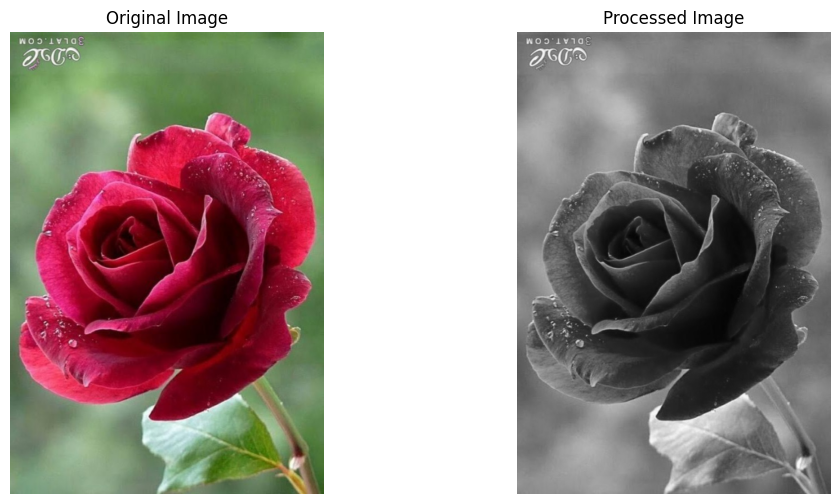

In [5]:
import matplotlib.pyplot as plt
import cv2
from google.colab import files

orig = cv2.cvtColor(cv2.imread("input.jpg"), cv2.COLOR_BGR2RGB)
proc = cv2.cvtColor(cv2.imread("output.jpg"), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(orig)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(proc)
plt.title("Processed Image")
plt.axis("off")
plt.show()

# لتحميل الصورة المعدلة على جهازك، شيل علامة # من السطر اللي جاي:
# files.download("output.jpg")

In [14]:
# 1. ترجمة كود C++
!g++ -O3 project.cpp -o project_cpp

import gradio as gr
import subprocess
import time
from PIL import Image

PROJECT_TITLE = "Image Processing Using Matrices"
SUPERVISOR_NAME = "Supervised by: Dr. Eman Gaber"
TEAM_MEMBERS = [
    "👑 Anas Hassan (Leader)",
    "👤 Mariam Essam",
    "👤 Mariam Sherif",
    "👤 Noura Nasr",
    "👤 Ali Ahmed",
    "👤 Hager Mohamed"
]

OP_MAP = {
    "🎨 Grayscale — تحويل لرمادي": "Grayscale",
    "☀️ Brightness — تعديل السطوع": "Brightness",
    "🔄 Horizontal Flip — قلب أفقي": "Flip",
    "🏁 Black & White — أبيض وأسود": "BW"
}

# المعادلات الرياضية لكل عملية لعرضها في الكارت التفاعلي
FORMULAS = {
    "🎨 Grayscale — تحويل لرمادي": """
    <div class="formula-box">
        <div class="formula-title">📐 معادلة التحويل للرمادي (Luminance Formula)</div>
        <div class="formula-math">Gray(y, x) = 0.299·R + 0.587·G + 0.114·B</div>
        <div class="formula-desc">يتم تحويل مصفوفة الألوان ثلاثية القنوات (RGB) إلى مصفوفة ثنائية الأبعاد (2D) بقيمة إضاءة واحدة لكل بكسل بناءً على حساسية العين البشرية.</div>
    </div>
    """,
    "☀️ Brightness — تعديل السطوع": """
    <div class="formula-box">
        <div class="formula-title">📐 معادلة تعديل السطوع (Brightness Clamping)</div>
        <div class="formula-math">I_new(y, x) = min(255, max(0, I_old(y, x) + β))</div>
        <div class="formula-desc">يتم جمع أو طرح معامل السطوع (β) على كل عنصر في المصفوفة مع حصر الناتج بين 0 و 255 لمنع تشوه الألوان (Overflow).</div>
    </div>
    """,
    "🔄 Horizontal Flip — قلب أفقي": """
    <div class="formula-box">
        <div class="formula-title">📐 معادلة الانعكاس الأفقي (Matrix Reflection)</div>
        <div class="formula-math">M_new[y][W - 1 - x] = M_old[y][x]</div>
        <div class="formula-desc">تتم إعادة ترتيب أعمدة المصفوفة أفقياً بحيث ينتقل العمود الأول ليصبح الأخير، دون أي تغيير في قيم ألوان البكسلات نفسها.</div>
    </div>
    """,
    "🏁 Black & White — أبيض وأسود": """
    <div class="formula-box">
        <div class="formula-title">📐 معادلة العتبة الثنائية (Binary Thresholding)</div>
        <div class="formula-math">B(y, x) = 255 if Gray(y, x) ≥ T else 0</div>
        <div class="formula-desc">يتم تحويل الصورة إلى مصفوفة ثنائية تحتوي على قيمتين فقط: 255 (أبيض) للقيم الأكبر من العتبة (T)، و 0 (أسود) للقيم الأصغر.</div>
    </div>
    """
}

def update_formula_card(operation_label):
    return FORMULAS.get(operation_label, "")

def process_single(input_img, operation_label, brightness_val, threshold_val):
    if input_img is None:
        return None, "⚠️ Upload an image first to inspect live 2D pixel matrices...", ""
    input_img.save("input.jpg")
    op_code = OP_MAP[operation_label]

    start_t = time.time()
    res = subprocess.run(
        ["./project_cpp", op_code, str(int(brightness_val)), str(int(threshold_val))],
        capture_output=True, text=True, check=True
    )
    elapsed_ms = (time.time() - start_t) * 1000

    w, h = input_img.size
    stats_html = f"""
    <div class="stats-bar">
        <span>📐 <b>Matrix Size:</b> {h} × {w} pixels</span>
        <span>🔢 <b>Total Elements:</b> {w*h:,} pixels</span>
        <span>⚡ <b>C++ Execution Time:</b> {elapsed_ms:.1f} ms</span>
    </div>
    """
    return Image.open("output.jpg"), res.stdout, stats_html

def run_cpp_all(input_img, brightness_val, threshold_val):
    if input_img is None:
        return None, None, None, None
    input_img.save("input.jpg")
    subprocess.run(
        ["./project_cpp", "all", str(int(brightness_val)), str(int(threshold_val))],
        check=True
    )
    return (
        Image.open("out_grayscale.jpg"),
        Image.open("out_brightness.jpg"),
        Image.open("out_flipped.jpg"),
        Image.open("out_bw.jpg")
    )

with open("project.cpp", "r") as f:
    cpp_source_code = f.read()

custom_css = """
/* إجبار الوضع الداكن الكامل وإلغاء أي خلفيات بيضاء من Gradio */
:root, body, .gradio-container {
    --background-fill-primary: #0b0e17 !important;
    --background-fill-secondary: #131724 !important;
    --block-background-fill: #131724 !important;
    --block-border-color: #232a3d !important;
    --input-background-fill: #181d2e !important;
    --border-color-primary: #262e45 !important;
    --body-text-color: #f1f5f9 !important;
    background-color: #0b0e17 !important;
    color: #f1f5f9 !important;
    font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
}

.header-box {
    background: linear-gradient(135deg, #141829 0%, #211838 100%);
    border: 1px solid #352f5b;
    border-radius: 16px;
    padding: 18px;
    text-align: center;
    margin-bottom: 14px;
    box-shadow: 0 8px 30px rgba(0,0,0,0.5);
}
.supervisor-badge {
    display: inline-block;
    background: #281f47;
    border: 1px solid #7c3aed;
    color: #ddd6fe;
    padding: 5px 18px;
    border-radius: 20px;
    font-weight: bold;
    font-size: 14px;
    margin-bottom: 12px;
}
.team-container {
    display: flex;
    flex-wrap: wrap;
    justify-content: center;
    gap: 8px;
}
.member-badge {
    background: #121624;
    border: 1px solid #2e3650;
    color: #e2e8f0;
    padding: 5px 14px;
    border-radius: 20px;
    font-size: 13px;
}
.leader-badge {
    background: linear-gradient(90deg, #4c3575, #372948);
    border: 1px solid #a78bfa;
    color: #fff;
    font-weight: bold;
}

/* عناوين مربعات الصور */
.panel-title-orig {
    background: linear-gradient(90deg, #0f2537, #16364d);
    border: 1px solid #255270;
    color: #7dd3fc;
    text-align: center;
    padding: 10px;
    border-radius: 10px;
    font-weight: bold;
    font-size: 16px;
    margin-bottom: 8px;
}
.panel-title-proc {
    background: linear-gradient(90deg, #281640, #381e57);
    border: 1px solid #663a9c;
    color: #e879f9;
    text-align: center;
    padding: 10px;
    border-radius: 10px;
    font-weight: bold;
    font-size: 16px;
    margin-bottom: 8px;
}

/* صندوق رفع الصور الداكن بحد متقطع */
.dark-upload [data-testid="image"] {
    background-color: #101420 !important;
    border: 2px dashed #4f46e5 !important;
    border-radius: 14px !important;
}
.dark-upload [data-testid="image"]:hover {
    border-color: #38bdf8 !important;
    background-color: #141a29 !important;
}
.dark-upload button[aria-label="Click to upload or drop files"] > * {
    opacity: 0 !important;
}
.dark-upload button[aria-label="Click to upload or drop files"]::before {
    content: "📤";
    font-size: 48px;
    display: block;
    margin-bottom: 8px;
}
.dark-upload button[aria-label="Click to upload or drop files"]::after {
    content: "اسحب الصورة هنا أو اختر ملفًا\\A الصيغ المدعومة: JPG • JPEG • PNG • BMP • WEBP";
    white-space: pre-line;
    color: #e2e8f0;
    font-size: 15px;
    font-weight: bold;
    line-height: 1.6;
    text-align: center;
    display: block;
}
.dark-output [data-testid="image"] {
    background-color: #101420 !important;
    border: 1px solid #283047 !important;
    border-radius: 14px !important;
}

.arrow-box {
    display: flex;
    align-items: center;
    justify-content: center;
    height: 330px;
    font-size: 36px;
    color: #a855f7;
    text-shadow: 0 0 15px rgba(168, 85, 247, 0.6);
}

/* شريط الإحصائيات تحت الصور */
.stats-bar {
    display: flex;
    justify-content: space-around;
    background: #131826;
    border: 1px solid #26304a;
    border-radius: 10px;
    padding: 10px 15px;
    margin: 10px 0 14px 0;
    font-size: 14px;
    color: #cbd5e1;
    direction: ltr;
}
.stats-bar b {
    color: #38bdf8;
}

.section-header {
    color: #7dd3fc;
    font-size: 16px;
    font-weight: bold;
    border-bottom: 1px solid #232a3d;
    padding-bottom: 8px;
    margin-bottom: 12px;
}
.dark-card {
    background-color: #131724 !important;
    border: 1px solid #232a3d !important;
    border-radius: 14px !important;
    padding: 16px !important;
}

/* أزرار العمليات بدون أي خلفية بيضاء */
.custom-radio, .custom-radio > div {
    background: transparent !important;
    border: none !important;
    box-shadow: none !important;
    padding: 0 !important;
}
.custom-radio .wrap {
    display: flex !important;
    flex-direction: column !important;
    gap: 10px !important;
    background: transparent !important;
}
.custom-radio label {
    background: #1a2033 !important;
    border: 1px solid #2d3652 !important;
    border-radius: 10px !important;
    padding: 12px 16px !important;
    color: #f1f5f9 !important;
    font-weight: bold !important;
    font-size: 15px !important;
    transition: all 0.2s ease !important;
}
.custom-radio label:hover {
    border-color: #7c3aed !important;
    background: #212840 !important;
}

/* شاشة المصفوفة الحية بدون إطار أبيض */
.matrix-terminal, .matrix-terminal > div {
    background: transparent !important;
    border: none !important;
    padding: 0 !important;
}
.matrix-terminal textarea {
    background-color: #06090e !important;
    color: #00ff66 !important;
    font-family: 'Courier New', Courier, monospace !important;
    font-size: 13px !important;
    line-height: 1.45 !important;
    border: 1px solid #1a382c !important;
    border-radius: 10px !important;
    direction: ltr !important;
    text-align: left !important;
}

/* كارت المعادلة الرياضية في الجزء الأيمن */
.formula-box {
    background: linear-gradient(135deg, #161c2e 0%, #1d1833 100%);
    border: 1px solid #362f5c;
    border-radius: 12px;
    padding: 16px;
    margin-top: 16px;
}
.formula-title {
    color: #c084fc;
    font-weight: bold;
    font-size: 15px;
    margin-bottom: 10px;
}
.formula-math {
    background: #0b0e17;
    border: 1px solid #2b344d;
    color: #38bdf8;
    font-family: 'Courier New', Courier, monospace;
    font-size: 15px;
    font-weight: bold;
    padding: 12px;
    border-radius: 8px;
    text-align: center;
    direction: ltr;
    margin-bottom: 10px;
}
.formula-desc {
    color: #cbd5e1;
    font-size: 13.5px;
    line-height: 1.6;
}

.gradient-btn {
    background: linear-gradient(90deg, #0ea5e9 0%, #8b5cf6 100%) !important;
    border: none !important;
    color: white !important;
    font-weight: bold !important;
    font-size: 16px !important;
    padding: 14px !important;
    border-radius: 12px !important;
    box-shadow: 0 4px 15px rgba(139, 92, 246, 0.4) !important;
    margin-top: 10px !important;
}

/* كارت العمليات الأربع */
.op-row-card {
    background: linear-gradient(135deg, #151926 0%, #1d2236 100%);
    border: 1px solid #323b59;
    border-radius: 14px;
    padding: 20px;
    height: 260px;
    display: flex;
    align-items: center;
    justify-content: space-between;
    direction: ltr;
}
.op-en { font-size: 20px; font-weight: bold; color: #38bdf8; margin-bottom: 6px; }
.op-ar { font-size: 16px; color: #cbd5e1; }
.op-arrow { font-size: 36px; color: #a855f7; }
"""

team_html = "".join([
    f'<span class="member-badge {"leader-badge" if i == 0 else ""}">{name}</span>'
    for i, name in enumerate(TEAM_MEMBERS)
])

header_html = f"""
<div class="header-box">
    <h1 style="margin:0 0 10px 0; font-size:24px; color:#fff;">🖼️ {PROJECT_TITLE} (C++ Engine)</h1>
    <div class="supervisor-badge">🎓 {SUPERVISOR_NAME}</div>
    <div class="team-container">{team_html}</div>
</div>
"""

def make_op_card(en_title, ar_title):
    return f"""
    <div class="op-row-card">
        <div>
            <div class="op-en">{en_title}</div>
            <div class="op-ar">({ar_title})</div>
        </div>
        <div class="op-arrow">➡️</div>
    </div>
    """

with gr.Blocks(css=custom_css, theme=gr.themes.Base()) as app:
    gr.HTML(header_html)

    with gr.Tabs():
        # التبويب الأول: الاستوديو التفاعلي
        with gr.Tab("🎛️ الاستوديو التفاعلي"):
            with gr.Row():
                with gr.Column(scale=5):
                    gr.HTML('<div class="panel-title-orig">🖼️ الصورة الأصلية</div>')
                    studio_in = gr.Image(
                        type="pil", show_label=False, height=330,
                        sources=["upload", "clipboard"], elem_classes="dark-upload"
                    )

                with gr.Column(scale=1, min_width=50):
                    gr.HTML('<div class="arrow-box">➡️</div>')

                with gr.Column(scale=5):
                    gr.HTML('<div class="panel-title-proc">✨ الصورة المعدلة</div>')
                    studio_out = gr.Image(
                        type="pil", show_label=False, height=330, elem_classes="dark-output"
                    )

            # شريط إحصائيات المصفوفة وسرعة التنفيذ
            stats_display = gr.HTML("")

            with gr.Row():
                # العمود الأيسر: العمليات + المصفوفة الحية
                with gr.Column(scale=1, elem_classes="dark-card"):
                    gr.HTML('<div class="section-header">🧮 اختر العملية الرياضية</div>')
                    op_selector = gr.Radio(
                        list(OP_MAP.keys()),
                        value="🎨 Grayscale — تحويل لرمادي",
                        show_label=False,
                        elem_classes="custom-radio"
                    )
                    gr.HTML('<div class="section-header" style="margin-top:16px;">📟 مصفوفة البكسلات الحية (C++ Matrix)</div>')
                    matrix_display = gr.Textbox(
                        lines=13, max_lines=13, show_label=False, interactive=False,
                        value="Upload an image to inspect live 2D pixel matrices before & after processing...",
                        elem_classes="matrix-terminal"
                    )

                # العمود الأيمن: معاملات الضبط + الزرار + كارت المعادلة الرياضية
                with gr.Column(scale=1, elem_classes="dark-card"):
                    gr.HTML('<div class="section-header">🎛️ معاملات الضبط</div>')
                    bright_slider = gr.Slider(-150, 150, value=60, step=5, label="☀️ السطوع (Brightness β)")
                    thresh_slider = gr.Slider(0, 255, value=127, step=1, label="🏁 عتبة الأبيض والأسود (Threshold)")
                    apply_btn = gr.Button("⚡ تطبيق وتحديث المصفوفة", elem_classes="gradient-btn")

                    # كارت المعادلة الرياضية الحية
                    formula_card = gr.HTML(FORMULAS["🎨 Grayscale — تحويل لرمادي"])

            # تحديث تلقائي عند تغيير العملية أو تحريك السلايدر أو الضغط على الزر
            op_selector.change(fn=update_formula_card, inputs=op_selector, outputs=formula_card)
            op_selector.change(fn=process_single, inputs=[studio_in, op_selector, bright_slider, thresh_slider], outputs=[studio_out, matrix_display, stats_display])
            bright_slider.release(fn=process_single, inputs=[studio_in, op_selector, bright_slider, thresh_slider], outputs=[studio_out, matrix_display, stats_display])
            thresh_slider.release(fn=process_single, inputs=[studio_in, op_selector, bright_slider, thresh_slider], outputs=[studio_out, matrix_display, stats_display])
            studio_in.change(fn=process_single, inputs=[studio_in, op_selector, bright_slider, thresh_slider], outputs=[studio_out, matrix_display, stats_display])
            apply_btn.click(fn=process_single, inputs=[studio_in, op_selector, bright_slider, thresh_slider], outputs=[studio_out, matrix_display, stats_display])

        # التبويب الثاني: العمليات الأربع
        with gr.Tab("🖼️ العمليات الأربع"):
            with gr.Row():
                all_in = gr.Image(
                    type="pil", show_label=False, height=260,
                    sources=["upload", "clipboard"], elem_classes="dark-upload"
                )
                with gr.Column(elem_classes="dark-card"):
                    all_bright_slider = gr.Slider(-150, 150, value=60, step=5, label="☀️ السطوع (Brightness β)")
                    all_thresh_slider = gr.Slider(0, 255, value=127, step=1, label="🏁 عتبة الأبيض والأسود (Threshold)")
                    run_all_btn = gr.Button("⚡ تطبيق وعرض العمليات الأربع معاً", elem_classes="gradient-btn")

            gr.HTML('<div class="section-header" style="margin-top:18px;">📊 نتائج العمليات الأربع (Image Processing Results)</div>')

            with gr.Row():
                with gr.Column(scale=4): gr.HTML(make_op_card("1. Grayscale", "درجات الرمادي"))
                with gr.Column(scale=6): out_gray = gr.Image(type="pil", show_label=False, height=260, elem_classes="dark-output")

            with gr.Row():
                with gr.Column(scale=4): gr.HTML(make_op_card("2. Brightness Adjustment", "تعديل السطوع"))
                with gr.Column(scale=6): out_bright = gr.Image(type="pil", show_label=False, height=260, elem_classes="dark-output")

            with gr.Row():
                with gr.Column(scale=4): gr.HTML(make_op_card("3. Horizontal Flip", "القلب الأفقي"))
                with gr.Column(scale=6): out_flip = gr.Image(type="pil", show_label=False, height=260, elem_classes="dark-output")

            with gr.Row():
                with gr.Column(scale=4): gr.HTML(make_op_card("4. Black and White", "أبيض وأسود"))
                with gr.Column(scale=6): out_bw = gr.Image(type="pil", show_label=False, height=260, elem_classes="dark-output")

            run_all_btn.click(
                fn=run_cpp_all,
                inputs=[all_in, all_bright_slider, all_thresh_slider],
                outputs=[out_gray, out_bright, out_flip, out_bw]
            )

        # التبويب الثالث: كود الـ C++
        with gr.Tab("💻 كود الـ C++"):
            gr.Markdown("### الكود المصدري المنفذ للمصفوفات (`project.cpp`)")
            gr.Code(value=cpp_source_code, language="cpp")

app.launch(share=True)

/tmp/ipykernel_1759/4125138591.py:392: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=custom_css, theme=gr.themes.Base()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://04b13b8491e47bfbcf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
